In [1]:
import pandas as pd
import sqlite3 as sql
import matplotlib.pyplot as plt

In [2]:
conn = sql.connect('chinook.db')
conn

In [3]:
pd.read_sql_query('select * from sqlite_master',conn)

,type,name,tbl_name,rootpage,sql
0,table,album,album,2,CREATE TABLE [album]\n(\n [album_id] INTEGE...
1,table,artist,artist,3,CREATE TABLE [artist]\n(\n [artist_id] INTE...
2,table,customer,customer,4,CREATE TABLE [customer]\n(\n [customer_id] ...
3,table,employee,employee,5,CREATE TABLE [employee]\n(\n [employee_id] ...
4,table,genre,genre,6,CREATE TABLE [genre]\n(\n [genre_id] INTEGE...
5,table,invoice,invoice,7,CREATE TABLE [invoice]\n(\n [invoice_id] IN...
6,table,invoice_line,invoice_line,8,CREATE TABLE [invoice_line]\n(\n [invoice_l...
7,table,media_type,media_type,9,CREATE TABLE [media_type]\n(\n [media_type_...
8,table,playlist,playlist,10,CREATE TABLE [playlist]\n(\n [playlist_id] ...
9,table,playlist_track,playlist_track,11,CREATE TABLE [playlist_track]\n(\n [playlis...


In [4]:
def sql_query(q):
    return pd.read_sql_query(q,conn)

In [5]:
sql_query('select * from sqlite_master where type = "table"')

,type,name,tbl_name,rootpage,sql
0,table,album,album,2,CREATE TABLE [album]\n(\n [album_id] INTEGE...
1,table,artist,artist,3,CREATE TABLE [artist]\n(\n [artist_id] INTE...
2,table,customer,customer,4,CREATE TABLE [customer]\n(\n [customer_id] ...
3,table,employee,employee,5,CREATE TABLE [employee]\n(\n [employee_id] ...
4,table,genre,genre,6,CREATE TABLE [genre]\n(\n [genre_id] INTEGE...
5,table,invoice,invoice,7,CREATE TABLE [invoice]\n(\n [invoice_id] IN...
6,table,invoice_line,invoice_line,8,CREATE TABLE [invoice_line]\n(\n [invoice_l...
7,table,media_type,media_type,9,CREATE TABLE [media_type]\n(\n [media_type_...
8,table,playlist,playlist,10,CREATE TABLE [playlist]\n(\n [playlist_id] ...
9,table,playlist_track,playlist_track,11,CREATE TABLE [playlist_track]\n(\n [playlis...


## Q1. Write a query to list the top 10 genres with the highest number of tracks. (Show in bar plot)

                genre  num_tracks
0                Rock        1297
1               Latin         579
2               Metal         374
3  Alternative & Punk         332
4                Jazz         130
5            TV Shows          93
6               Blues          81
7           Classical          74
8               Drama          64
9            R&B/Soul          61


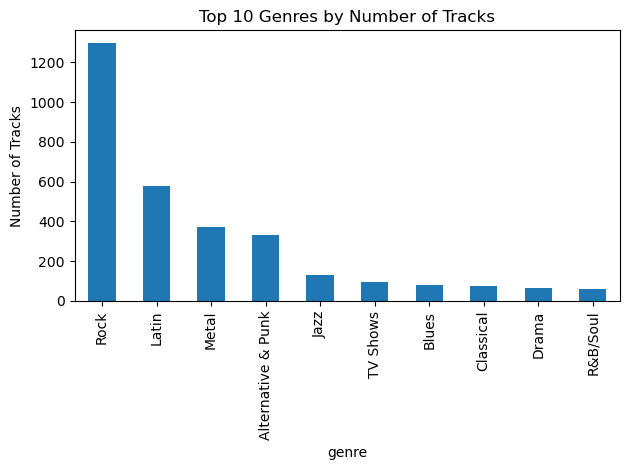

In [7]:
q1 = """
SELECT g.name AS genre, COUNT(t.track_id) AS num_tracks
FROM track t
JOIN genre g 
ON
t.genre_id = g.genre_id
GROUP BY g.name
ORDER BY num_tracks DESC
LIMIT 10;
"""
df1 = sql_query(q1)
print(df1)

df1.plot(kind='bar', x='genre', y='num_tracks', legend=False,
         title='Top 10 Genres by Number of Tracks')
plt.ylabel('Number of Tracks')
plt.tight_layout()
plt.show()

## Q2. Write a query to list the top 10 albums that contain the most tracks.

In [8]:
q2 = """
SELECT al.title AS album, ar.name AS artist, COUNT(t.track_id) AS num_tracks
FROM track t
JOIN album al 
ON
t.album_id = al.album_id
JOIN artist ar ON al.artist_id = ar.artist_id
GROUP BY al.album_id
ORDER BY num_tracks DESC
LIMIT 10;
"""
sql_query(q2)

,album,artist,num_tracks
0,Greatest Hits,Lenny Kravitz,57
1,Minha Historia,Chico Buarque,34
2,Unplugged,Eric Clapton,30
3,"Lost, Season 3",Lost,26
4,"Lost, Season 1",Lost,25
5,"The Office, Season 3",The Office,25
6,My Way: The Best Of Frank Sinatra [Disc 1],Frank Sinatra,24
7,"Lost, Season 2",Lost,24
8,"Battlestar Galactica (Classic), Season 1",Battlestar Galactica (Classic),24
9,Afrociberdelia,Chico Science & Nação Zumbi,23


## Q3. Write a query to find the top 10 customers who spent the most money.

In [10]:
q3 = """
SELECT c.customer_id,
       c.first_name || ' ' || c.last_name AS customer,
       ROUND(SUM(inv.total), 2) AS total_spent
FROM customer c
JOIN invoice inv 
ON
c.customer_id = inv.customer_id
GROUP BY c.customer_id
ORDER BY total_spent DESC
LIMIT 10;
"""
sql_query(q3)

,customer_id,customer,total_spent
0,5,František Wichterlová,144.54
1,6,Helena Holý,128.70
2,46,Hugh O'Reilly,114.84
3,58,Manoj Pareek,111.87
4,1,Luís Gonçalves,108.90
5,13,Fernanda Ramos,106.92
6,34,João Fernandes,102.96
7,3,François Tremblay,99.99
8,42,Wyatt Girard,99.99
9,17,Jack Smith,98.01


## Q4. Write a query to find the top 5 artists who generated the highest revenue from track sales.

In [11]:
q4 = """
SELECT ar.name AS artist,
       ROUND(SUM(il.unit_price * il.quantity), 2) AS revenue
FROM invoice_line il
JOIN track t  
ON 
il.track_id = t.track_id
JOIN album al 
ON
t.album_id = al.album_id
JOIN artist ar 
ON
al.artist_id = ar.artist_id
GROUP BY ar.artist_id
ORDER BY revenue DESC
LIMIT 5;
"""
sql_query(q4)

,artist,revenue
0,Queen,190.08
1,Jimi Hendrix,185.13
2,Red Hot Chili Peppers,128.70
3,Nirvana,128.70
4,Pearl Jam,127.71


## Q5. Countries by Average Revenue per Invoice

In [11]:
q5 = """
SELECT billing_country AS country,
       ROUND(AVG(total), 2) AS avg_revenue_per_invoice,
       COUNT(*) AS num_invoices
FROM invoice
GROUP BY billing_country
ORDER BY avg_revenue_per_invoice DESC;
"""
sql_query(q5)

,country,avg_revenue_per_invoice,num_invoices
0,Czech Republic,9.11,30
1,Spain,8.91,11
2,Ireland,8.83,13
3,United Kingdom,8.77,28
4,India,8.72,21
5,Belgium,8.63,7
6,Germany,8.16,41
7,Australia,8.12,10
8,Norway,8.03,9
9,USA,7.94,131


## Q6. Write a query to find the media type with number of tracks.


In [12]:
q6 = """
SELECT m.name AS media_type, COUNT(t.track_id) AS num_tracks
FROM track t
JOIN media_type m ON t.media_type_id = m.media_type_id
GROUP BY m.name
ORDER BY num_tracks DESC;
"""
sql_query(q6)

,media_type,num_tracks
0,MPEG audio file,3034
1,Protected AAC audio file,237
2,Protected MPEG-4 video file,214
3,AAC audio file,11
4,Purchased AAC audio file,7


## Q7. Which artists have released tracks in more than one genre?

In [12]:
q7 = """
SELECT ar.name AS artist,
       COUNT(t.genre_id) AS num_genres,
       GROUP_CONCAT(g.name) AS genres
FROM artist ar
JOIN album al 
ON 
ar.artist_id = al.artist_id
JOIN track t  
ON
al.album_id  = t.album_id
JOIN genre g  
ON
t.genre_id   = g.genre_id
GROUP BY ar.artist_id
HAVING COUNT(t.genre_id) > 1
ORDER BY num_genres DESC;
"""
sql_query(q7)

,artist,num_genres,genres
0,Iron Maiden,213,"Rock,Rock,Rock,Rock,Rock,Rock,Rock,Rock,Rock,R..."
1,U2,135,"Rock,Rock,Rock,Rock,Rock,Rock,Rock,Rock,Rock,R..."
2,Led Zeppelin,114,"Rock,Rock,Rock,Rock,Rock,Rock,Rock,Rock,Rock,R..."
3,Metallica,112,"Metal,Metal,Metal,Metal,Metal,Metal,Metal,Meta..."
4,Lost,92,"TV Shows,TV Shows,TV Shows,TV Shows,TV Shows,D..."
...,...,...,...
131,English Concert & Trevor Pinnock,2,"Classical,Classical"
132,The Posies,2,"Rock,Rock"
133,Karsh Kale,2,"Electronica/Dance,Electronica/Dance"
134,Habib Koité and Bamada,2,"World,World"


## Q8. Write a query to list the top 10 longest tracks by duration.

## Q9. Top 5 Revenue Share percentage by Artist (Pie Chart)

                  artist  revenue
0                  Queen   190.08
1           Jimi Hendrix   185.13
2  Red Hot Chili Peppers   128.70
3                Nirvana   128.70
4              Pearl Jam   127.71


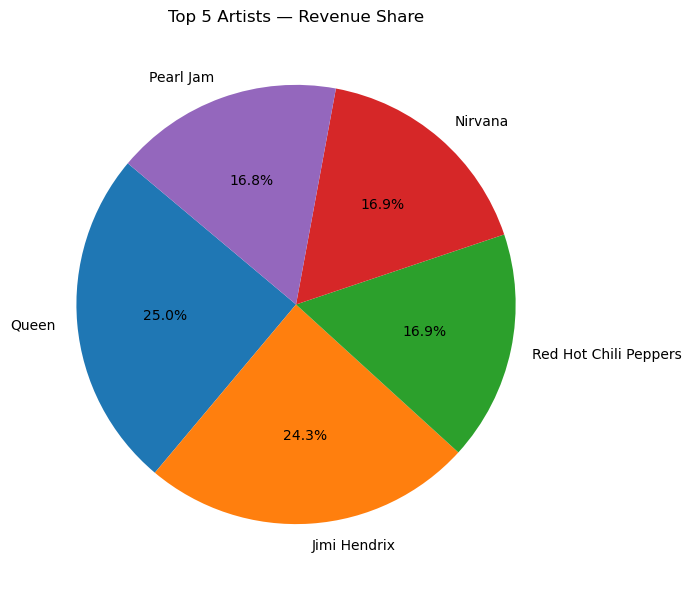

In [13]:
q9 = """
SELECT ar.name AS artist,
       SUM(il.unit_price * il.quantity) AS revenue
FROM invoice_line il
JOIN track t  
ON
il.track_id = t.track_id
JOIN album al 
ON
t.album_id = al.album_id
JOIN artist ar 
ON
al.artist_id = ar.artist_id
GROUP BY ar.artist_id
ORDER BY revenue DESC
LIMIT 5;
"""
df9 = sql_query(q9)
print(df9)

plt.figure(figsize=(7, 7))
plt.pie(df9['revenue'], labels=df9['artist'], autopct='%1.1f%%',
        startangle=140)
plt.title('Top 5 Artists — Revenue Share')
plt.tight_layout()
plt.show()

## Q10. Revenue by Genre (Rock, Latin, Metal) in Each Country (Stacked Column Chart)

genre           Latin   Metal    Rock
country                              
USA             21.78  122.76  555.39
Canada          12.87   71.28  329.67
France          26.73   53.46  208.89
Brazil          12.87   72.27  202.95
Germany          7.92   43.56  192.06
United Kingdom   6.93   30.69  164.34
Czech Republic  20.79   22.77  141.57
Portugal         5.94   27.72  106.92
India            5.94   21.78  100.98
Ireland         19.80    5.94   71.28
Chile            3.96   10.89   60.39
Sweden           1.98    6.93   59.40
Spain            4.95   12.87   45.54
Finland          1.98    9.90   45.54
Hungary          0.99   18.81   43.56


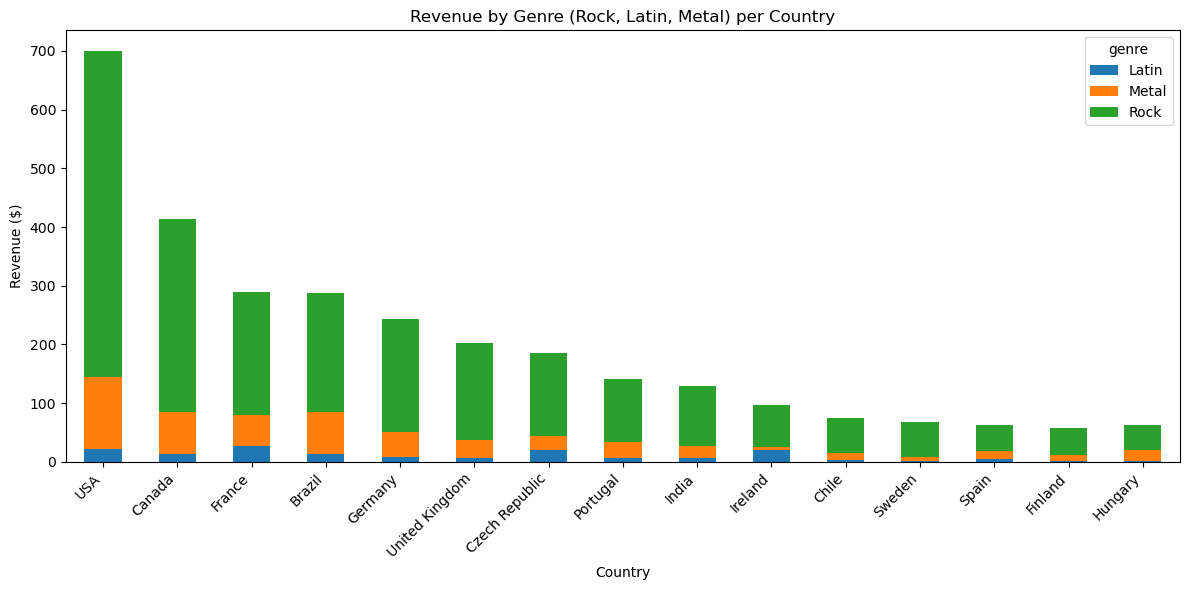

In [18]:
q10 = """
SELECT i.billing_country AS country,
       g.name AS genre,
       ROUND(SUM(il.unit_price * il.quantity), 2) AS revenue
FROM invoice_line il
JOIN invoice i 
ON
il.invoice_id = i.invoice_id
JOIN track t   
ON
il.track_id   = t.track_id
JOIN genre g   
ON
t.genre_id    = g.genre_id
WHERE g.name IN ('Rock', 'Latin', 'Metal')
GROUP BY i.billing_country, g.name
ORDER BY i.billing_country;
"""
df10 = sql_query(q10)

pivot = df10.pivot(index='country', columns='genre', values='revenue')
pivot = pivot.sort_values(by='Rock', ascending=False).head(15)
print(pivot)

pivot.plot(kind='bar', stacked=True, figsize=(12, 6),
           title='Revenue by Genre (Rock, Latin, Metal) per Country')
plt.ylabel('Revenue ($)')
plt.xlabel('Country')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()
